# Feed Forward neural network
* A complete network from scratch
  - Feed Forward
  - Layers
  - Backpropagation
* Check gradients against jax
## Architecture
* MSE as cost function
* Flexible number of hidden layers and nodes
  - One hidden layer using 50 nodes
  - two hidden layers using 50 and 100 nodes 
  - Sigmoid function activation for hidden layers
* Initial weights with normal distribution
* Initialize bias , how?
* Final output activation function: which one?
* How do you set up the design matrice?

## Train and compare
* Compare the results with OLS from project 1
* Use the best data set and best polynomial degree wrt MSE




## Packages

In [18]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp   
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# The data

(350, 1) (350,)


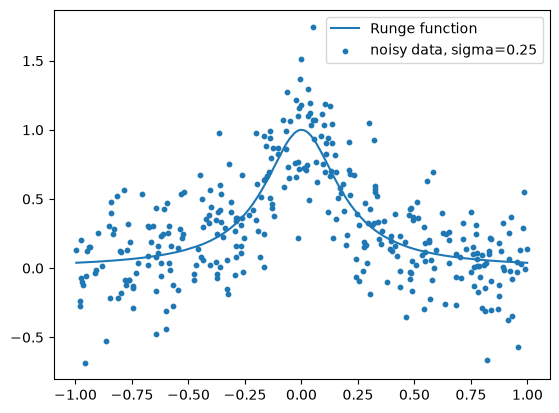

In [19]:
# The data of project 1, as a starting point for part b)
np.random.seed(2026)

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 350 # 350 in Project 1
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.25 # 0.25 in Project 1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

## Data processing
Creates a design matrice out of input values x of chosen degree and  an array out of targets y.   
Splits the data into training and test data and 
scales the data, if "Split and scale" as Process input.

In [20]:
from sklearn.model_selection import train_test_split

def Data_process(x, y, degree, 
    test_size = 0.3, Process="Split and scale"):
    x = np.asarray(x).reshape(-1)
    y = np.asarray(y).reshape(-1,1)
    X = np.column_stack([x**power for power in range(degree + 1)])

    if Process == "Split and scale":
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=2026
        )

        # Scale polynomial features, leaving the intercept column unchanged.
        mean = X_train[:, 1:].mean(axis=0)
        std = X_train[:, 1:].std(axis=0)
        mean[0] = 0
        std[std == 0] = 1

        X_train[:, 1:] = (X_train[:, 1:] - mean) / std
        X_test[:, 1:] = (X_test[:, 1:] - mean) / std

        y_mean = y_train.mean(axis=0)
        y_train_c = y_train - y_mean

        return X_train, X_test, y_train_c, y_test, y_mean

    return X, y

### Activation functions and MSE


In [21]:
def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))
def sigmoid_der(z):
    s = sigmoid(z)
    return s*(1 - s)
# Alternatively sigmoid_der = jax.grad(jnp.sum(sigmoid(z)))
# Identity
def identity(z):
    return z

def identity_der(z):
    return np.ones_like(z)

# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)
# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)

def mse(predict, target):
    return jnp.mean((predict - target) ** 2)
def mse_der(predict, target): # Derivative of cost function
    return 2*(predict - target)/predict.size # Mean brings a factor of 1/N, derivative brings factor 2
# Alternatively: mse_der = jax.grad(mse(predict, target))

# Neural Network Class: Batched
### LLM Declaration: 
#### NeuralNetwork()
I am using LLM chatgpt GPT-6 Luna for learning about the usage of classes.  
The skeleton is from "Exercisesweek42.ipynb" Exercise 8 of repository MachinelearningUiO. 
I am using this skeleton, along with the solution of exerciseweek42.ipynb, to create the class. 

OpenAI assistance with translating the functions 
into working class functions.
OpenAI help with debugging the jax gradients.
OpenAI help with debugging the compute_gradients.

#### Data_processing()
--> Changed y = np.asarray(y) into y = npasarray(y).reshape(-1,1) to get y into the right shape (n,) - > (n,1) : Why this is so i do not understand, but i do understand that without this change, the code wont work in the feed forward saver as the dimensions of the last layer get off.


### Caution
Gradient methods should by handled outside, by performing
general operations on layer_grad list using functions
or classes seperate from the neural network.  
I still chose to include a short plain gradient descent
method for evolving the gradients, for testing.

In [22]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        seed,
    ):
        self.network_input_size = network_input_size
        self.layer_output_sizes = layer_output_sizes
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders 
        self.cost_fun = cost_fun
        self.cost_der = cost_der
        self.rng = np.random.default_rng(seed) # Reproducability

        # create layers = [(W , b)] with random normal weights and biases
        layers = []

        i_size = network_input_size
        for layer_output_size in layer_output_sizes:
            W = self.rng.standard_normal((i_size, layer_output_size)) / np.sqrt(i_size) # dele på sqrt(i_size)? Ja for batched
            b = np.zeros(layer_output_size) + 0.01 #np.random.randn(layer_output_size)
            layers.append((W, b))

            i_size = layer_output_size
        
        self.layers = layers

    def predict(self, inputs):
        # Simple feed forward pass
        a = jnp.asarray(inputs) 
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def cost(self, inputs, targets):
        predictions = self.predict(inputs)
        mse = self.cost_fun(predictions,targets)
        return mse

    def _feed_forward_saver(self, inputs):
        layer_inputs = []
        zs = []
        a = jnp.asarray(inputs)
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            #print("a",a.shape)
            #print("W",W.shape)
            #print("b", b.shape)
            z = a @ W + b
            zs.append(z)
            a = activation_func(z)
        return layer_inputs, zs, a 

    def compute_gradient(self, inputs, targets):
        # Denne gjøres med LA
        # dC_dW = dC_da @ da_dz @ dz_dW
        # dC_db = dC_da @ da_dz @ dz_db
        layer_inputs, sz, predict = self._feed_forward_saver(
            inputs)
        layer_grads = [() for layer in self.layers]

        for l in reversed(range(len(self.layers))):
            layer_input, z, activation_der = layer_inputs[l], sz[l], self.activation_ders[l]

            if l == (len(self.layers) - 1): # last layer
                dC_da = self.cost_der(predict, targets)
            else:
                (W, b) = self.layers[l + 1]
                #print("layer", l)
                #print("predictions:", predict.shape)
                #print("targets:", targets.shape)
                #print("dC_dz:", dC_dz.shape)
                #print("W:", W.shape)
                dC_da = dC_dz @ (W.T) 

            dC_dz = dC_da * activation_der(z) # Hadamard
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis=0) # what happened here?

            layer_grads[l] = (dC_dW, dC_db)
            #print("layer", l)
            #print("predictions:", predict.shape)
            #print("targets:", targets.shape)
            #print("dC_dz:", dC_dz.shape)
        return layer_grads
    
    def accuracy(self, predictions, targets):
        one_hot_predictions = np.zeros(predictions.shape)

        for i, prediction in enumerate(predictions):
            one_hot_predictions[i, np.argmax(prediction)] = 1
        return accuracy_score(one_hot_predictions, targets) # ski-kit function

    # These last two methods are not needed in the project, but they can be nice to have!
    # This should be External! But i can try use plain gradient
    # BEWARE: Using this function will change the local variable self.layers in the object
    def update_weights_plain(self, layer_grads, gamma=0.05):
        self.layers = [
        (W - gamma * W_g, b - gamma * b_g)
        for (W, b), (W_g, b_g) in zip(self.layers, layer_grads)]


    # jax solution
    # The first one has a layers parameter so that you can use jax.grad on it.
    
    def jax_compliant_predict(self, layers, inputs):
        a = jnp.asarray(inputs)

        for (W, b), activation_func in zip(layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def jax_cost(self, layers, inputs, targets):
        predictions = self.jax_compliant_predict(layers, inputs)
        mse = self.cost_fun(predictions, targets)
        return mse

    def jax_gradient(self, inputs, targets):
        grads = jax.grad(self.jax_cost,argnums = 0)(self.layers, inputs, targets)
        return grads

In [23]:
#jax_grads = NN.jax_gradient(self.layers, X_train, y_train)

In [24]:
#  Creat e and 8 degree design matrice of x, scale, split into training & test data
X_train, X_test, y_train, y_test, y_mean = Data_process(x, y, degree=8, test_size=0.3, Process="Split and scale")
network_input_size = X_train.shape[-1] # 9
network_output_size = 1 # same order as y
layer_output_sizes1 = [50, 1]
activation_funcs1 =[sigmoid, identity]
activation_ders1 =[sigmoid_der, identity_der]
layer_output_sizes2 = [50, 100, 1]
activation_funcs2 =[sigmoid, sigmoid, identity]
activation_ders2 =[sigmoid_der,sigmoid_der, identity_der]
cost_fun=mse
cost_der=mse_der

#np.random.seed(2026)
NN1 = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed = 2026
)
NN2 = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes2,
    activation_funcs=activation_funcs2,
    activation_ders=activation_ders2,
    cost_fun=mse,
    cost_der=mse_der,
    seed = 2026
)

# 1 Layer neural network
print("1 Layer Neural Network")
predict1 = NN1.predict(X_test) + y_mean
cost1 = NN1.cost_fun(predict1, y_test)
gradients1 = NN1.compute_gradient(X_train, y_train)

jax_grad1 = NN1.jax_gradient(X_train, y_train)
print("agree with jax.grad:", [(np.allclose(dW, dW_j), np.allclose(db, db_j))
                                for (dW, db), (dW_j, db_j) in zip(gradients1, jax_grad1)])

gam = 0.01
# Before update:
print("MSE predict no training      :", cost1)
# Testing one update: Plain GD
NN1.update_weights_plain(gradients1, gamma=gam)
predict21 = NN1.predict(X_test) + y_mean
cost21 = NN1.cost_fun(predict21, y_test)
print("MSE predict after one update.:", cost21)
# Second update: Plain GD
gradients21 = NN1.compute_gradient(X_train, y_train)
NN1.update_weights_plain(gradients21, gamma=gam)
predict31 = NN1.predict(X_test) + y_mean
cost31 = NN1.cost_fun(predict31, y_test)
print("MSE predict after two updates:", cost31)
# Third update: Plain GD
gradients31 = NN1.compute_gradient(X_train, y_train)
NN1.update_weights_plain(gradients31, gamma=gam)
predict41 = NN1.predict(X_test) + y_mean
cost41 = NN1.cost_fun(predict41, y_test)
print("MSE predict after three updates:", cost41)



# 2 Layer Neural Network
print("---------------------")
print("2 Layers Neural Network")
predict2 = NN2.predict(X_test) + y_mean
cost2 = NN2.cost_fun(predict2, y_test)
gradients12 = NN2.compute_gradient(X_train, y_train)

jax_grad2 = NN2.jax_gradient(X_train, y_train)
print("agree with jax.grad:", [(np.allclose(dW, dW_j), np.allclose(db, db_j))
                                for (dW, db), (dW_j, db_j) in zip(gradients12, jax_grad2)])

#cost2 = []
# Before update:
print("MSE predict no training      :", cost2)
# Testing one update: Plain GD
NN2.update_weights_plain(gradients12, gamma=gam)
predict2 = NN2.predict(X_test) + y_mean
cost2 = NN2.cost_fun(predict2, y_test)
print("MSE predict after one update.:", cost2)
# Second update: Plain GD
gradients22 = NN2.compute_gradient(X_train, y_train)
NN2.update_weights_plain(gradients22, gamma=gam)
predict3 = NN2.predict(X_test) + y_mean
cost3 = NN2.cost_fun(predict3, y_test)
print("MSE predict after two updates:", cost3)
# Third update: Plain GD Test
gradients32 = NN2.compute_gradient(X_train, y_train)
NN2.update_weights_plain(gradients32, gamma=gam)
predict4 = NN2.predict(X_test) + y_mean
cost4 = NN2.cost_fun(predict4, y_test)
print("MSE predict after three updates:", cost4)

1 Layer Neural Network
agree with jax.grad: [(True, True), (True, True)]
MSE predict no training      : 0.4292542883755887
MSE predict after one update.: 0.28763537211160184
MSE predict after two updates: 0.21839768391028247
MSE predict after three updates: 0.18459315491579073
---------------------
2 Layers Neural Network
agree with jax.grad: [(True, True), (True, True), (True, True)]
MSE predict no training      : 0.2643571717852912
MSE predict after one update.: 0.2020019502336223
MSE predict after two updates: 0.18811781473156317
MSE predict after three updates: 0.18455595905690328


Project 1 OLS: best MSE polynomial order:  
Comparison

* Compare results and give a critical discussion
* Make an analysis of the learning rates employed to find the optimal MSE score
* Test both stochastic gradient descent with RMSprop and Adam
* Test Plain gradient descent with different learning rates

In [62]:
# 8 degree OLS MSE: 0.08489369549855502
"Closed form solution from Project 2"
OLS_theta = np.linalg.pinv(X_train) @ y_train

# Trenings-MSE. Both measurements and predictions are scaled and centred.
OLS_predict_train = X_train @ OLS_theta
MSE_OLS_train = np.mean((y_train - OLS_predict_train)**2)

# Test-MSE. Put back mean before comparison
OLS_predict_test = X_test @ OLS_theta + y_mean
MSE_OLS_test = np.mean((y_test - OLS_predict_test)**2)

print("OLS training MSE:", MSE_OLS_train)
print("OLS test MSE:", MSE_OLS_test)

OLS training MSE: 0.06544660866859343
OLS test MSE: 0.08489369549855463


# OLS Comparison
Nå må jeg først løse train_netowrk, med SGD Adam + RMS

## LLM Declaration
LLM note: ChatGPT (GPT-6, October 2026) suggested code snippets for the minibatch training loop and the layer-wise Adam and RMSprop updates, and helped identify a mismatch in the optimizer state format. The code was adapted by the author and verified by the author.

In [90]:
def zero_state(layers):
    "LLM assisted"
    return [
        (
            np.zeros_like(W),  # mW
            np.zeros_like(b),  # mb
            np.zeros_like(W),  # vW
            np.zeros_like(b),  # vb
        )
        for W, b in layers
    ]

def optimiser_step_layers(
    layers, layer_grads, state, t, method, gamma,
    beta1=0.9, beta2=0.999, rho=0.99, eps=1e-8
):  
    "LLM Assisted"

    if method == "plain":
        new_layers = [
            (W - gamma * dW, b - gamma * db)
            for (W, b), (dW, db) in zip(layers, layer_grads)
        ]
        return new_layers, state

    # ADAM and RMSprop
    new_layers = []
    new_state = []
    
    for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
        layers, layer_grads, state
    ):
        dW = np.asarray(dW)
        db = np.asarray(db)

        if method == "rmsprop":
            vW = rho * vW + (1 - rho) * dW**2
            vb = rho * vb + (1 - rho) * db**2

            W = W - gamma * dW / (np.sqrt(vW) + eps)
            b = b - gamma * db / (np.sqrt(vb) + eps)

        elif method == "adam":
            mW = beta1 * mW + (1 - beta1) * dW
            mb = beta1 * mb + (1 - beta1) * db
            vW = beta2 * vW + (1 - beta2) * dW**2
            vb = beta2 * vb + (1 - beta2) * db**2

            mW_hat = mW / (1 - beta1**t)
            mb_hat = mb / (1 - beta1**t)
            vW_hat = vW / (1 - beta2**t)
            vb_hat = vb / (1 - beta2**t)

            W = W - gamma * mW_hat / (np.sqrt(vW_hat) + eps)
            b = b - gamma * mb_hat / (np.sqrt(vb_hat) + eps)

        else:
            raise ValueError("method må være 'adam' eller 'rmsprop'")

        new_layers.append((W, b))
        new_state.append((mW, mb, vW, vb))

    return new_layers, new_state
    
def step_length(t, t0, t1):
    """A decaying learning-rate schedule."""
    return t0 / (t + t1)

def train_sgd(
    network, X, y, method="adam",
    epochs=100, batch_size=5, gamma=0.001,  schedule=None, seed=2026
):
    "LLM Assisted"
    rng = np.random.default_rng(seed)

    X = np.asarray(X)
    y = np.asarray(y).reshape(-1, 1)

    # Tilstanden er en liste med tupler, ett for hvert lag.
    state = None if method == "plain" else zero_state(network.layers)
    t = 0
    history = []
    history_test = []
    for epoch in range(epochs):
        # Bland rekkefølgen på datapunktene for hver epoke.
        indices = rng.permutation(len(X))
        # Minibatch
        for start in range(0, len(X), batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X[batch]
            y_batch = y[batch]

            # Hent gradientene fra nettverksobjektet.
            layer_grads = network.compute_gradient(X_batch, y_batch)

            # Tell minibatchoppdateringer. Adam bruker t til korreksjon
            # for oppstartsfasen.
            t += 1
            gamma = gamma if schedule is None else step_length(t - 1, *schedule)
            network.layers, state = optimiser_step_layers(
                network.layers,
                layer_grads,
                state,
                t,
                method,
                gamma
            )

        # Kostnaden etter at hele treningssettet har vært gjennom én gang.
        epoch_cost = float(network.cost(X, y))
        history.append(epoch_cost)
        # Test kostnad 
        predict = network.predict(X_test) + y_mean
        epoch_cost_test = float(network.cost_fun(predict, y_test))
        history_test.append(epoch_cost_test)

    return history, history_test

# 1 Layer with 50 nodes

## Gamma values

0.001
OLS test-MSE: 0.08489369549855463
Adam last prediction test MSE: 0.09571708783115955
RMSprop last prediction test MSE: 0.09967964790712923
---
OLS train-MSE: 0.06544660866859343
Adam last prediction train MSE: 0.07789959142101766
RMSprop last prediction train MSE: 0.07846778958920791


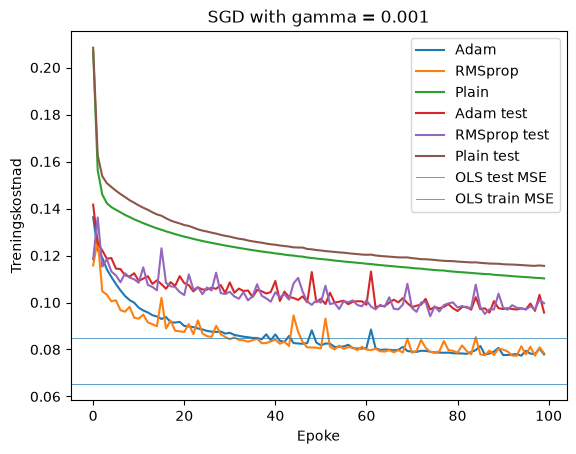

0.0005
OLS test-MSE: 0.08489369549855463
Adam last prediction test MSE: 0.1000884759954422
RMSprop last prediction test MSE: 0.10156412494778516
---
OLS train-MSE: 0.06544660866859343
Adam last prediction train MSE: 0.0817112065748642
RMSprop last prediction train MSE: 0.08129934286836325


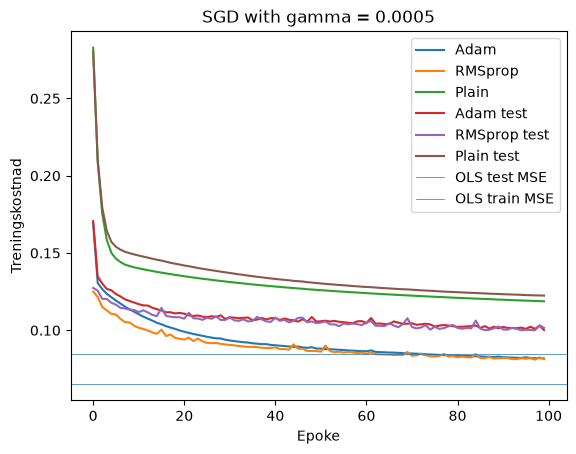

0.0001
OLS test-MSE: 0.08489369549855463
Adam last prediction test MSE: 0.11035581339058953
RMSprop last prediction test MSE: 0.10894421885412772
---
OLS train-MSE: 0.06544660866859343
Adam last prediction train MSE: 0.09958066781586196
RMSprop last prediction train MSE: 0.09629820011169914


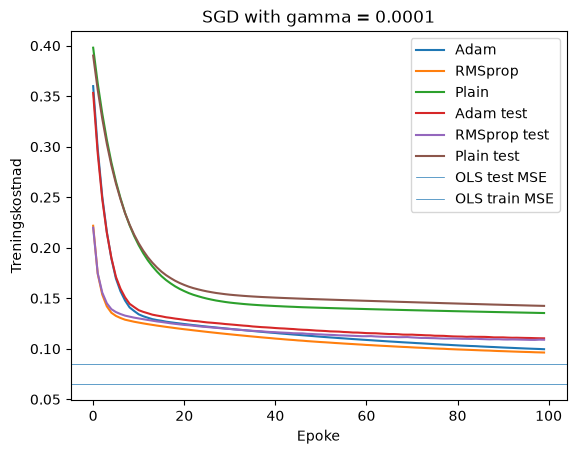

In [ ]:
# Gamma = 0.001
gamma_list = [0.001, 0.0005, 0.0001]
for gamma_i in gamma_list:

    NN_plain = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes1,
        activation_funcs=activation_funcs1,
        activation_ders=activation_ders1,
        cost_fun=mse,
        cost_der=mse_der,
        seed=2026)

    plain_history_train, plain_history_test = train_sgd(
        NN_plain, X_train, y_train,
        method="plain",
        epochs=100,
        batch_size=10,
        gamma=gamma_i,
    )

    NN_adam = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes1,
        activation_funcs=activation_funcs1,
        activation_ders=activation_ders1,
        cost_fun=mse,
        cost_der=mse_der,
        seed=2026
    )

    adam_history_train, adam_history_test = train_sgd(
        NN_adam, X_train, y_train,
        method="adam",
        epochs=100,
        batch_size=10,
        gamma=gamma_i,
    )

    NN_rmsprop = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes1,
        activation_funcs=activation_funcs1,
        activation_ders=activation_ders1,
        cost_fun=mse,
        cost_der=mse_der,
        seed=2026
    )

    rmsprop_history_train, rmsprop_history_test = train_sgd(
        NN_rmsprop, X_train, y_train,
        method="rmsprop",
        epochs=100,
        batch_size=10,
        gamma=gamma_i
    )
    print(gamma_i)
    print("OLS test-MSE:", MSE_OLS_test)
    print("Adam last prediction test MSE:", (adam_history_test[-1]))
    print("RMSprop last prediction test MSE:", rmsprop_history_test[-1])
    print("---")
    print("OLS train-MSE:", MSE_OLS_train)
    print("Adam last prediction train MSE:", (adam_history_train[-1]))
    print("RMSprop last prediction train MSE:", rmsprop_history_train[-1])

    plt.title(f"SGD with gamma = {gamma_i}")
    plt.plot(plain_history_train, "--", color = "blue", label = "Plain train")
    plt.plot(plain_history_test, color = "blue", label = "Plain test")
    plt.plot(adam_history_train, "--", color = "red", label="Adam train")
    plt.plot(adam_history_test, "--", color = "red", label="Adam test")
    plt.plot(rmsprop_history_train, "--", color = "green", label="RMSprop")
    plt.plot(rmsprop_history_test, color = "green", label="RMSprop test")
    plt.axhline(y = MSE_OLS_test, label = "OLS test MSE", lw = 0.5)
    plt.axhline(y = MSE_OLS_train, label = "OLS train MSE", lw = 0.5)
    plt.xlabel("Epoch")
    plt.ylabel("Cost (MSE)")
    plt.legend()
    plt.show()

## Schedule

OLS test-MSE: 0.08489369549855463
Adam last prediction test MSE: 0.09590504628720581
RMSprop last prediction test MSE: 0.08950912487652858
---
OLS train-MSE: 0.06544660866859343
Adam last prediction train MSE: 0.07595596679623477
RMSprop last prediction train MSE: 0.06786357815682251


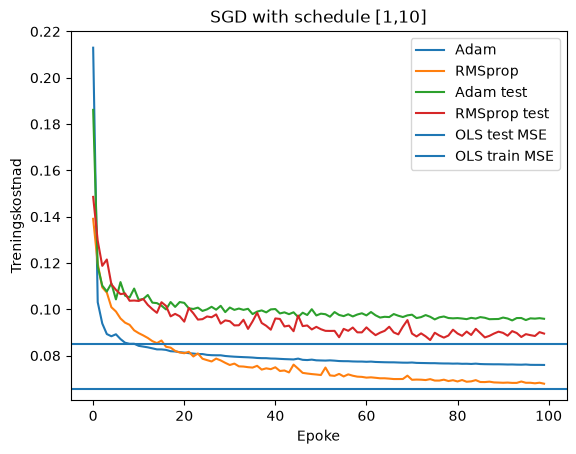

In [ ]:
# Schedule = [1,10]
NN_plain_s = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed=2026
)

plain_history_s, plain_history_test_s = train_sgd(
    NN_plain, X_train, y_train,
    method = "plain",
    epochs = 100,
    batch_size = 10,
    gamma = 0.001,
    schedule = [1, 10]
)


NN_adam_s = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed=2026
)

adam_history_train_s, adam_history_test_s = train_sgd(
    NN_adam_s, X_train, y_train,
    method="adam",
    epochs=100,
    batch_size=10,
    gamma=0.001,
    schedule = [1,10]
)

NN_rmsprop_s = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed=2026
)

rmsprop_history_train_s, rmsprop_history_test_s = train_sgd(
    NN_rmsprop_s, X_train, y_train,
    method="rmsprop",
    epochs=100,
    batch_size=10,
    gamma=0.001,
    schedule = [1,10]
)

print("OLS test-MSE:", MSE_OLS_test)
print("Adam last prediction test MSE:", (adam_history_test_s[-1]))
print("RMSprop last prediction test MSE:", rmsprop_history_test_s[-1])
print("---")
print("OLS train-MSE:", MSE_OLS_train)
print("Adam last prediction train MSE:", (adam_history_train_s[-1]))
print("RMSprop last prediction train MSE:", rmsprop_history_train_s[-1])


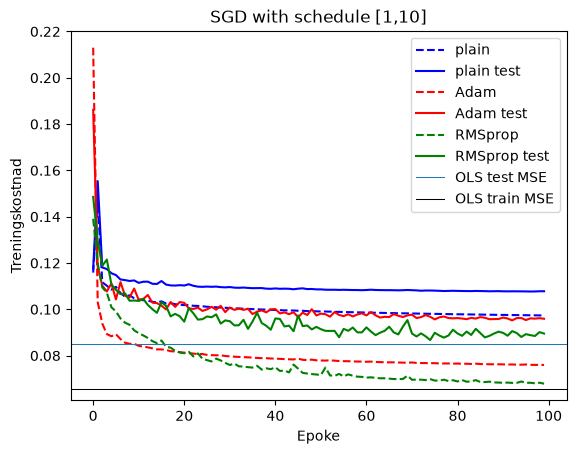

In [ ]:

plt.title("SGD with schedule [1,10]")
plt.plot(plain_history_s, "--", color = "blue", label = "plain train")
plt.plot(plain_history_test_s, color = "blue", label = "plain test")
plt.plot(adam_history_train_s, "--", color = "red", label="Adam train")
plt.plot(adam_history_test_s, color = "red", label="Adam test")
plt.plot(rmsprop_history_train_s, "--", color = "green", label="RMSprop train")
plt.plot(rmsprop_history_test_s, color = "green", label="RMSprop test")
plt.axhline(y = MSE_OLS_test, label = "OLS test MSE", lw = 0.75)
plt.axhline(y = MSE_OLS_train, label = "OLS train MSE", lw = 0.75, color = "black")
plt.xlabel("Epoch")
plt.ylabel("Cost (MSE)")
plt.legend()
plt.show()

# Two layers with 50 and 100 nodes

## Gamma values

In [104]:
# Gamma = 0.001
gamma_list = [0.001, 0.0005, 0.0001]
for gamma_i in gamma_list:

    NN_plain = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes2,
        activation_funcs=activation_funcs2,
        activation_ders=activation_ders2,
        cost_fun=mse,
        cost_der=mse_der,
        seed=2026)

    plain_history_train, plain_history_test = train_sgd(
        NN_plain, X_train, y_train,
        method="plain",
        epochs=100,
        batch_size=10,
        gamma=gamma_i,
    )

    NN_adam = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes2,
        activation_funcs=activation_funcs2,
        activation_ders=activation_ders2,
        cost_fun=mse,
        cost_der=mse_der,
        seed=2026
    )

    adam_history_train, adam_history_test = train_sgd(
        NN_adam, X_train, y_train,
        method="adam",
        epochs=100,
        batch_size=10,
        gamma=gamma_i,
    )

    NN_rmsprop = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes2,
        activation_funcs=activation_funcs2,
        activation_ders=activation_ders2,
        cost_fun=mse,
        cost_der=mse_der,
        seed=2026
    )

    rmsprop_history_train, rmsprop_history_test = train_sgd(
        NN_rmsprop, X_train, y_train,
        method="rmsprop",
        epochs=100,
        batch_size=10,
        gamma=gamma_i
    )
    print(gamma_i)
    print("OLS test-MSE:", MSE_OLS_test)
    print("Adam last prediction test MSE:", (adam_history_test[-1]))
    print("RMSprop last prediction test MSE:", rmsprop_history_test[-1])
    print("---")
    print("OLS train-MSE:", MSE_OLS_train)
    print("Adam last prediction train MSE:", (adam_history_train[-1]))
    print("RMSprop last prediction train MSE:", rmsprop_history_train[-1])
    
    plt.title(f"SGD with gamma = {gamma_i}")
    plt.plot(plain_history_train, "--", color = "blue", label = "Plain train")
    plt.plot(plain_history_test, color = "blue", label = "Plain test")
    plt.plot(adam_history_train, "--", color = "red", label="Adam train")
    plt.plot(adam_history_test, "--", color = "red", label="Adam test")
    plt.plot(rmsprop_history_train, "--", color = "green", label="RMSprop")
    plt.plot(rmsprop_history_test, color = "green", label="RMSprop test")
    plt.axhline(y = MSE_OLS_test, label = "OLS test MSE", lw = 0.5)
    plt.axhline(y = MSE_OLS_train, label = "OLS train MSE", lw = 0.5)
    plt.xlabel("Epoch")
    plt.ylabel("Cost (MSE)")
    plt.legend()
    plt.show()

KeyboardInterrupt: 

## Schedule

OLS test-MSE: 0.08489369549855463
Adam last prediction test MSE: 0.09590504628720581
RMSprop last prediction test MSE: 0.08950912487652858
---
OLS train-MSE: 0.06544660866859343
Adam last prediction train MSE: 0.07595596679623477
RMSprop last prediction train MSE: 0.06786357815682251


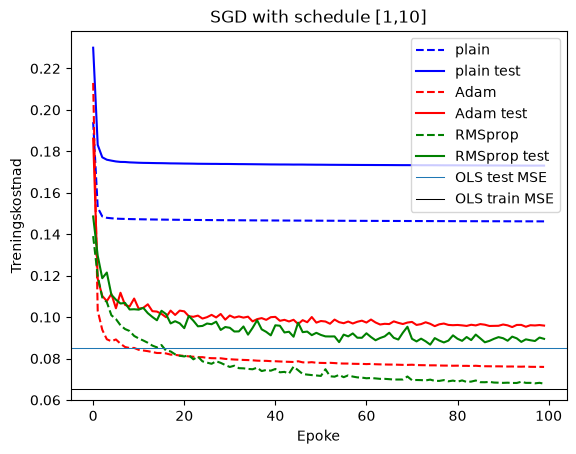

In [ ]:
# Schedule = [1,10]
NN_plain_s = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed=2026
)

plain_history_s, plain_history_test_s = train_sgd(
    NN_plain, X_train, y_train,
    method = "plain",
    epochs = 100,
    batch_size = 10,
    gamma = 0.001,
    schedule = [1, 10]
)


NN_adam_s = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed=2026
)

adam_history_train_s, adam_history_test_s = train_sgd(
    NN_adam_s, X_train, y_train,
    method="adam",
    epochs=100,
    batch_size=10,
    gamma=0.001,
    schedule = [1,10]
)

NN_rmsprop_s = NeuralNetwork(
    network_input_size=network_input_size,
    layer_output_sizes=layer_output_sizes1,
    activation_funcs=activation_funcs1,
    activation_ders=activation_ders1,
    cost_fun=mse,
    cost_der=mse_der,
    seed=2026
)

rmsprop_history_train_s, rmsprop_history_test_s = train_sgd(
    NN_rmsprop_s, X_train, y_train,
    method="rmsprop",
    epochs=100,
    batch_size=10,
    gamma=0.001,
    schedule = [1,10]
)

print("OLS test-MSE:", MSE_OLS_test)
print("Adam last prediction test MSE:", (adam_history_test_s[-1]))
print("RMSprop last prediction test MSE:", rmsprop_history_test_s[-1])
print("---")
print("OLS train-MSE:", MSE_OLS_train)
print("Adam last prediction train MSE:", (adam_history_train_s[-1]))
print("RMSprop last prediction train MSE:", rmsprop_history_train_s[-1])


plt.title("SGD with schedule [1,10]")
plt.plot(plain_history_s, "--", color = "blue", label = "plain train")
plt.plot(plain_history_test_s, color = "blue", label = "plain test")
plt.plot(adam_history_train_s, "--", color = "red", label="Adam train")
plt.plot(adam_history_test_s, color = "red", label="Adam test")
plt.plot(rmsprop_history_train_s, "--", color = "green", label="RMSprop train")
plt.plot(rmsprop_history_test_s, color = "green", label="RMSprop test")
plt.axhline(y = MSE_OLS_test, label = "OLS test MSE", lw = 0.75)
plt.axhline(y = MSE_OLS_train, label = "OLS train MSE", lw = 0.75, color = "black")
plt.xlabel("Epoke")
plt.ylabel("Treningskostnad")
plt.legend()
plt.show()